# ¿Cuánto piden por un auto usado?

Trabajo práctico de Python para Ciencia de Datos · UADE

**Integrantes** · Facundo Rodrigues, Mateo Gimenez, Lautaro Acosta, Lucas Insabralde, Matias Sevilla y Bruno Herzig.

Queremos estimar el precio publicado en USD de un auto usado con su año, kilometraje, cilindrada, potencia, puertas y plazas. Cada fila corresponde a un aviso histórico de Mercado Libre Argentina. Para estimar el precio de una venta o una cotización actual harían falta otros datos.

La fuente es un archivo público de 10.191 avisos y 25 columnas, actualizado en febrero de 2024. Trabajamos con todos los avisos del CSV original que tienen condición `Usado` y moneda `USD`. `autos.csv` contiene las 4.047 filas de ese recorte y 16 columnas, entre ellas datos numéricos como año y precio y categóricos como marca y combustible. Conservamos los valores originales para mostrar la limpieza.

Para ejecutarlo, poné `TP_autos.ipynb` y `autos.csv` en la misma carpeta y abrí el notebook desde allí. Instalá las dependencias del README en el entorno de Python que elijas como kernel. Ejecutá las celdas de arriba hacia abajo.

[Cars publications prices - MercadoLibreARG, Ariel Rasgido, versión 1](https://www.kaggle.com/datasets/arielras/cars-publications-prices-mercadolibrearg)

## 1. Carga y revisión inicial

Leemos `autos.csv` con pandas. El separador de columnas es el punto y coma. Revisamos cuántas filas y columnas hay, los tipos y los valores faltantes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150})

original = pd.read_csv("autos.csv", sep=";")
print("Filas y columnas", original.shape)
original.info()
display(original[["brand", "model", "car_year", "km", "price"]].head())
display(original.isna().sum().rename("Faltantes").to_frame())

Filas y columnas (4047, 16)
<class 'pandas.DataFrame'>
RangeIndex: 4047 entries, 0 to 4046
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  4047 non-null   str    
 1   title               4047 non-null   str    
 2   condition           4047 non-null   str    
 3   currency            4047 non-null   str    
 4   car_year            4047 non-null   int64  
 5   brand               4047 non-null   str    
 6   model               4047 non-null   str    
 7   version             4047 non-null   str    
 8   km                  4047 non-null   str    
 9   price               4047 non-null   int64  
 10  fuel_type           4047 non-null   str    
 11  transmission        3931 non-null   str    
 12  engine              3922 non-null   str    
 13  engine_power        3787 non-null   str    
 14  doors               4047 non-null   int64  
 15  passenger_capacity  3825 non-null   fl

,brand,model,car_year,km,price
0,Volkswagen,Gol,2014,83000 km,4300
1,Volkswagen,Gol,2010,159000 km,4700
2,Volkswagen,Gol,2009,200000 km,4500
3,Volkswagen,Gol,2007,64126 km,6500
4,Volkswagen,Gol,2012,170000 km,4700


,Faltantes
id,0
title,0
condition,0
currency,0
car_year,0
brand,0
model,0
version,0
km,0
price,0


## 2. Limpieza

El ID identifica cada aviso. Buscamos las filas que comparten un ID, los años imposibles y el aviso cuyo título indica que el importe es un anticipo. En este último caso, el texto del aviso explica por qué ese importe quedaría fuera del análisis de precios completos. También verificamos que los kilómetros no sean negativos y que el precio sea positivo.

In [2]:
repetidos = original["id"].duplicated(keep=False)
display(original.loc[repetidos, ["id", "brand", "model", "car_year", "price"]])

anio_imposible = ~original["car_year"].between(1886, 2024)
display(original.loc[anio_imposible, ["id", "title", "car_year", "doors", "price"]])

menciona_anticipo = original["title"].str.contains("anticipo", case=False, na=False)
display(original.loc[menciona_anticipo, ["id", "title", "price"]])

,id,brand,model,car_year,price
3138,MLA1404982421,Ford,Ka,2017,11500
3400,MLA1404982421,Ford,Ka,2017,11500


,id,title,car_year,doors,price
911,MLA1639157994,Chevrolet Corsa 2007 1.6 Gl Aa Dh,436673,60252,4200


,id,title,price
2792,MLA1403304889,Fiat Uno 1.4 Way Pack Anticipo U$3400 Automoto...,3400


Los dos registros del ID repetido eran idénticos y conservamos uno solo. Quitamos el Chevrolet Corsa con año `436673` y el Fiat Uno cuyo título dice que los USD 3.400 son un anticipo. Convertimos el kilometraje de texto a número para poder calcular y graficar. La transmisión tiene faltantes y queda fuera del modelo, así que podemos conservar esos avisos. Después de limpiar quedan 4.044 filas con año, kilómetros y precio completos. Conservamos los precios altos que pasan los controles. Un precio poco habitual no demuestra que el aviso esté mal cargado. El Corsa con año imposible también declaraba 60.252 puertas. Para el modelo, pasamos cilindrada y potencia a números. Si el texto de cilindrada no es un número claro o queda fuera de un rango razonable de 0,5 a 8 L, tratamos el dato como faltante. Es el caso del valor 2.000 escrito como si fueran litros. Conservamos el aviso y más adelante completamos los campos que falten con medianas.

In [3]:
autos = original.drop_duplicates(subset="id").copy()
autos = autos[autos["car_year"].between(1886, 2024)].copy()
autos = autos[autos["id"] != "MLA1403304889"].copy()

autos["km"] = pd.to_numeric(autos["km"].str.replace(" km", "", regex=False), errors="coerce")

columnas_obligatorias = ["car_year", "km", "price"]
print("Avisos antes de limpiar", len(original))
print("Avisos después de limpiar", len(autos))
display(autos[columnas_obligatorias].isna().sum().rename("Faltantes").to_frame())
print("Kilometrajes negativos", (autos["km"] < 0).sum())
print("Precios no positivos", (autos["price"] <= 0).sum())

autos["cilindrada"] = pd.to_numeric(
    autos["engine"].str.replace(" L", "", regex=False), errors="coerce"
)
autos["potencia"] = pd.to_numeric(
    autos["engine_power"].str.replace(" hp", "", regex=False), errors="coerce"
)

autos.loc[~autos["cilindrada"].between(0.5, 8), "cilindrada"] = float("nan")

ficha = ["cilindrada", "potencia", "doors", "passenger_capacity"]
display(autos[ficha].isna().sum().rename("Faltantes para completar").to_frame())


Avisos antes de limpiar 4047
Avisos después de limpiar 4044


,Faltantes
car_year,0
km,0
price,0


Kilometrajes negativos 0
Precios no positivos 0


,Faltantes para completar
cilindrada,154
potencia,260
doors,0
passenger_capacity,222


## 3. Precios y kilometraje

Los histogramas muestran dónde se concentran los precios, el kilometraje y los años. Los boxplots marcan la mediana y los cuartiles. La mitad central de los avisos está entre USD 6.100 y USD 13.000, y entre 68.000 y 141.000 km. El año mediano es 2014. El precio medio ronda USD 10.896 y supera a la mediana de USD 8.700 por la cola de precios altos.

,price,km,car_year
count,4044.000000,4044.000000,4044.000000
mean,10896.214886,106858.897873,2013.844708
std,7453.779457,62226.857043,5.384602
min,1100.000000,500.000000,1990.000000
25%,6100.000000,68000.000000,2011.000000
50%,8700.000000,101000.000000,2014.000000
75%,13000.000000,141000.000000,2018.000000
max,82000.000000,999999.000000,2024.000000


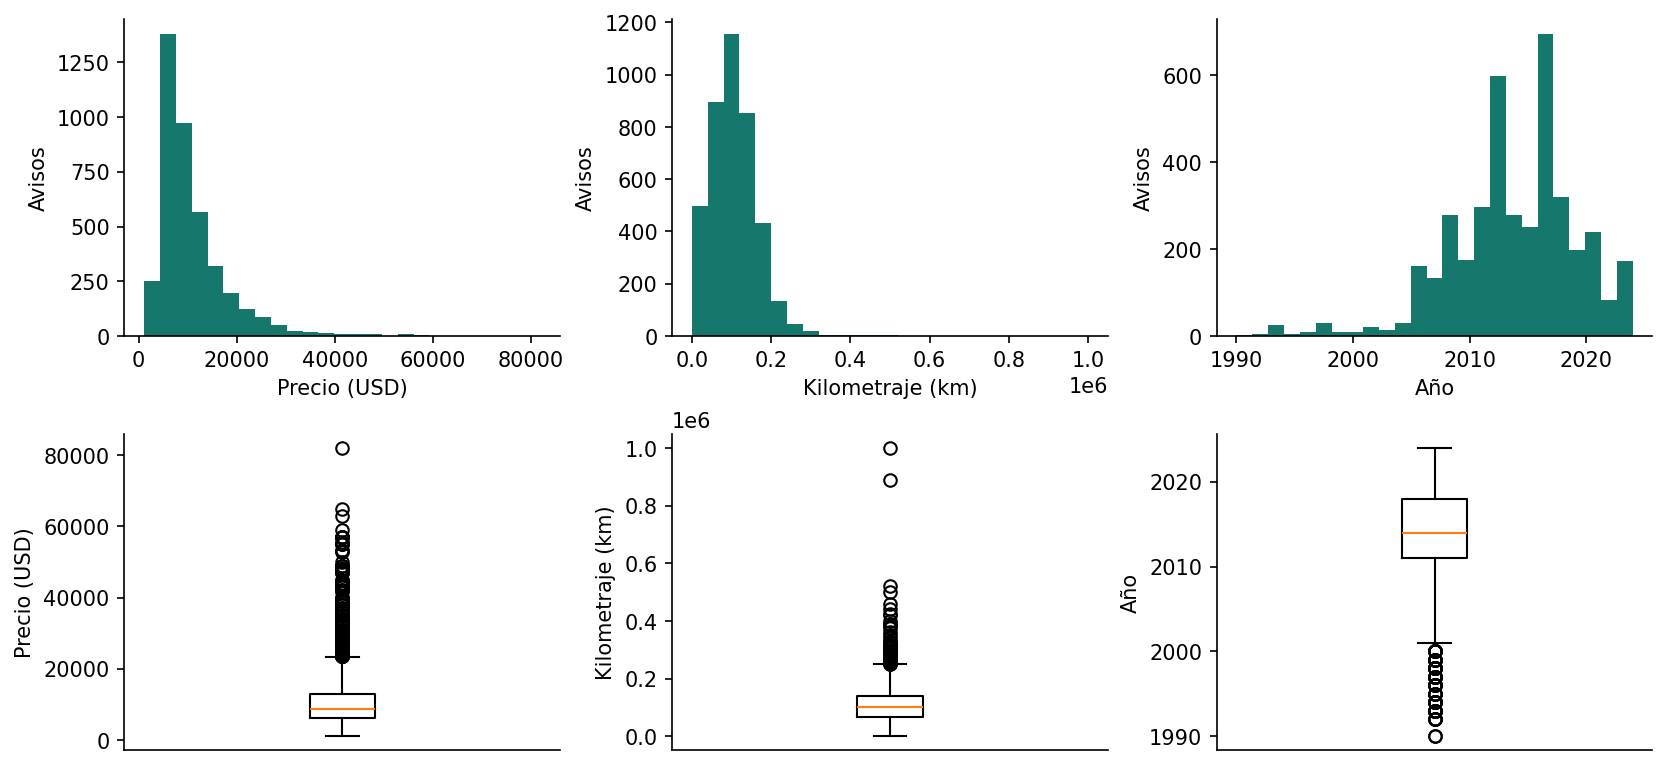

In [4]:
display(autos[["price", "km", "car_year"]].describe())

figura, ejes = plt.subplots(2, 3, figsize=(11, 5), layout="constrained")
variables = [("price", "Precio (USD)"), ("km", "Kilometraje (km)"), ("car_year", "Año")]

for i, (columna, etiqueta) in enumerate(variables):
    ejes[0, i].hist(autos[columna], bins=25, color="#16786d")
    ejes[0, i].set(xlabel=etiqueta, ylabel="Avisos")
    ejes[1, i].boxplot(autos[columna])
    ejes[1, i].set(ylabel=etiqueta, xticks=[])

plt.show()

## 4. Relación entre variables

Cada punto es un aviso. Comparamos el precio con el año y los kilómetros. El precio tiende a subir en autos más nuevos (correlación de Pearson de 0,59) y a bajar cuando aumenta el kilometraje (−0,51). En los gráficos, autos con el mismo año o kilometraje pueden tener precios muy distintos. El año del vehículo describe su fabricación. Para graficar una serie de precios harían falta fechas de publicación.

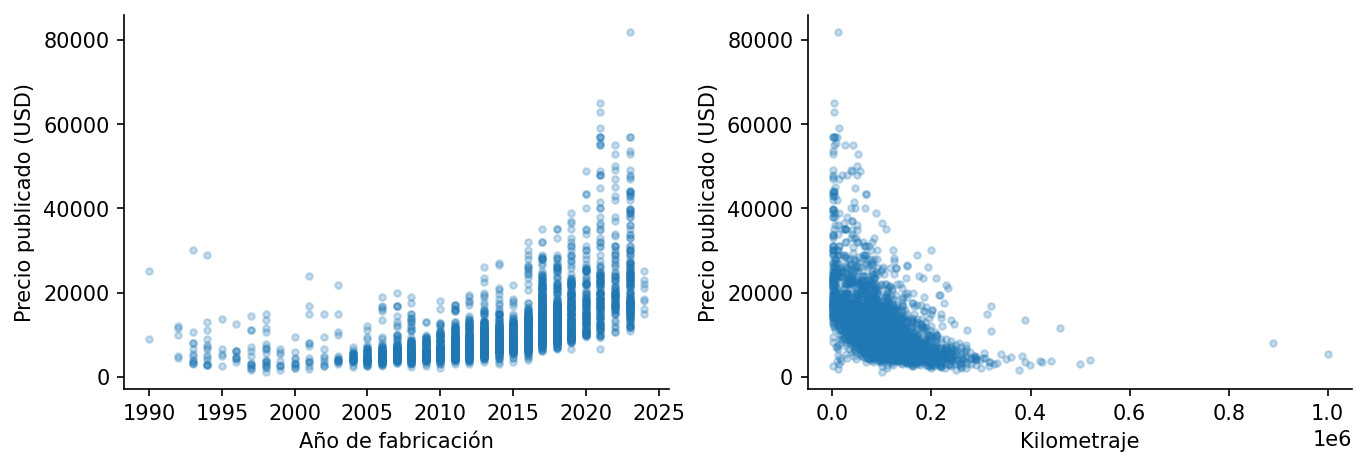

,car_year,km,price
car_year,1.000000,-0.609257,0.590185
km,-0.609257,1.000000,-0.513718
price,0.590185,-0.513718,1.000000


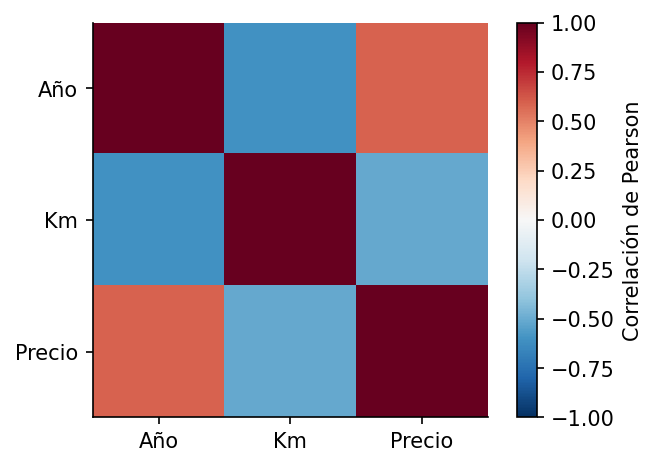

In [5]:
figura, ejes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
autos.plot.scatter(x="car_year", y="price", ax=ejes[0], alpha=0.25, s=10)
autos.plot.scatter(x="km", y="price", ax=ejes[1], alpha=0.25, s=10)
for eje in ejes:
    eje.set_ylabel("Precio publicado (USD)")
ejes[0].set_xlabel("Año de fabricación")
ejes[1].set_xlabel("Kilometraje")
plt.show()

correlaciones = autos[["car_year", "km", "price"]].corr()
display(correlaciones)
figura, eje = plt.subplots(figsize=(5, 3), layout="constrained")
imagen = eje.imshow(correlaciones, vmin=-1, vmax=1, cmap="RdBu_r")
eje.set_xticks([0, 1, 2], ["Año", "Km", "Precio"])
eje.set_yticks([0, 1, 2], ["Año", "Km", "Precio"])
figura.colorbar(imagen, ax=eje, label="Correlación de Pearson")
plt.show()

## 5. Precio por marca

Agrupamos los avisos por marca con `groupby`. Usamos la mediana para comparar el precio típico y la cantidad para saber cuántos avisos hay detrás de cada barra. Toyota tiene la mediana más alta de la muestra (USD 17.725 en 428 avisos). Cada marca reúne autos de varios modelos y edades, así que la comparación describe los avisos observados.

,avisos,mediana_usd
brand,,
Chevrolet,460,6550.0
Fiat,480,7000.0
Peugeot,750,7000.0
Renault,390,7800.0
Volkswagen,797,9000.0
Ford,576,10000.0
Honda,163,12500.0
Toyota,428,17725.0


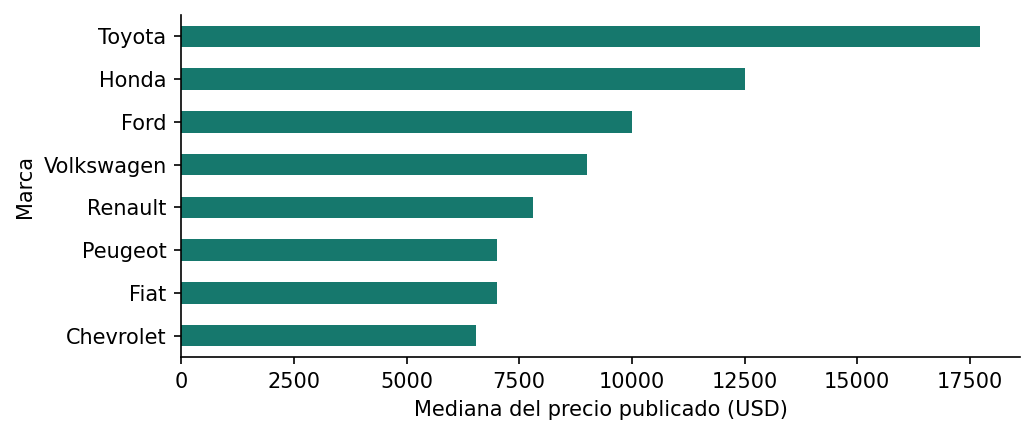

In [6]:
por_marca = autos.groupby("brand")["price"].agg(
    avisos="size", mediana_usd="median"
).sort_values("mediana_usd")

display(por_marca)
eje = por_marca["mediana_usd"].plot.barh(figsize=(7, 3), color="#16786d")
eje.set_xlabel("Mediana del precio publicado (USD)")
eje.set_ylabel("Marca")
plt.tight_layout()
plt.show()

## 6. Entrenamiento y prueba

Año, kilometraje, cilindrada, potencia, puertas y plazas forman `X`. El precio publicado en USD es el objetivo `y`. Reservamos el 20 % de las filas para la prueba final. `random_state=42` permite repetir la misma separación. Quitamos avisos con ID repetido, aunque autos de características parecidas pueden quedar en ambos conjuntos. Esta prueba mide el error sobre otros avisos de la misma fuente histórica.

In [7]:
from sklearn.model_selection import train_test_split

X = autos[["car_year", "km"] + ficha]
y = autos["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Avisos de entrenamiento", len(X_train))
print("Avisos de prueba", len(X_test))

Avisos de entrenamiento 3235
Avisos de prueba 809


## 7. Qué modelo elegimos

Comparamos los dos modelos de regresión vistos en la Unidad 7. La regresión lineal combina los seis datos de la ficha para estimar el precio. k-NN usa los precios de los avisos más parecidos según esos datos.

La validación cruzada divide el **entrenamiento** en cinco partes. Cada ronda ajusta el modelo con cuatro y mide el error en la restante. Usamos las mismas cinco divisiones para ambos modelos y elegimos el menor MAE promedio, es decir, el menor error absoluto promedio en dólares.

Los dos modelos completan los datos numéricos faltantes con la mediana. Es la misma idea que usar `fillna` con una mediana en pandas. `SimpleImputer` permite que el `Pipeline` calcule esas medianas solo con las filas de ajuste de cada ronda.

Para k-NN probamos tres cantidades de vecinos y dos formas de promediarlos. El promedio uniforme les da el mismo peso y el ponderado da más peso a los cercanos. El escalado evita que la unidad de kilómetros domine la distancia. Con `Pipeline`, los valores del escalado se aprenden en cada ronda usando solo sus filas de ajuste.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

particiones = KFold(n_splits=5)
criterio = "neg_mean_absolute_error"

lineal = Pipeline([
    ("completar", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression()),
])
errores_lineal = -cross_val_score(
    lineal, X_train, y_train, cv=particiones, scoring=criterio
)

vecinos = Pipeline([
    ("completar", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("knn", KNeighborsRegressor()),
])
opciones = {
    "knn__n_neighbors": [5, 15, 35],
    "knn__weights": ["uniform", "distance"],
}
busqueda = GridSearchCV(
    vecinos, opciones, cv=particiones, scoring=criterio, refit=False
)
busqueda.fit(X_train, y_train)

cantidad = busqueda.best_params_["knn__n_neighbors"]
pesos = "uniformes" if busqueda.best_params_["knn__weights"] == "uniform" else "por distancia"
comparacion = pd.DataFrame({
    "Modelo": ["Regresión lineal", "k-NN"],
    "Configuración": ["Seis datos numéricos", f"{cantidad} vecinos, pesos {pesos}"],
    "MAE de validación (USD)": [errores_lineal.mean(), -busqueda.best_score_],
}).set_index("Modelo")

ganador = comparacion["MAE de validación (USD)"].idxmin()
display(comparacion.round(2))
print("Modelo elegido:", ganador)

,Configuración,MAE de validación (USD)
Modelo,,
Regresión lineal,Seis datos numéricos,2959.02
k-NN,"5 vecinos, pesos por distancia",1539.76


Modelo elegido: k-NN


## 8. Cuánto se equivoca en la prueba

Ajustamos el modelo elegido con todo el entrenamiento y lo comparamos con una referencia simple: estimar siempre la mediana de precios del entrenamiento. El conjunto de prueba interviene recién en esta evaluación.

El MAE indica cuánto se aleja en promedio la estimación, en USD. El RMSE da más peso a los errores grandes. El R² mide cuánto mejora el ajuste frente a una predicción constante igual a la media del conjunto evaluado. Puede ser negativo cuando el ajuste resulta peor que esa referencia.

In [9]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

if ganador == "Regresión lineal":
    modelo = lineal
else:
    modelo = vecinos.set_params(**busqueda.best_params_)

modelo.fit(X_train, y_train)
prediccion = modelo.predict(X_test)
referencia = [y_train.median()] * len(y_test)

resultados = []
for nombre, estimaciones in [("Mediana de entrenamiento", referencia), (ganador, prediccion)]:
    resultados.append({
        "Modelo": nombre,
        "MAE (USD)": mean_absolute_error(y_test, estimaciones),
        "RMSE (USD)": root_mean_squared_error(y_test, estimaciones),
        "R²": r2_score(y_test, estimaciones),
    })

metricas = pd.DataFrame(resultados).set_index("Modelo")
display(metricas.round(2))

,MAE (USD),RMSE (USD),R²
Modelo,,,
Mediana de entrenamiento,4630.71,7415.26,-0.07
k-NN,1406.86,2625.82,0.87


La línea diagonal marca la coincidencia perfecta. Los puntos alejados de la línea ayudan a ver en qué casos la estimación queda corta o se pasa.

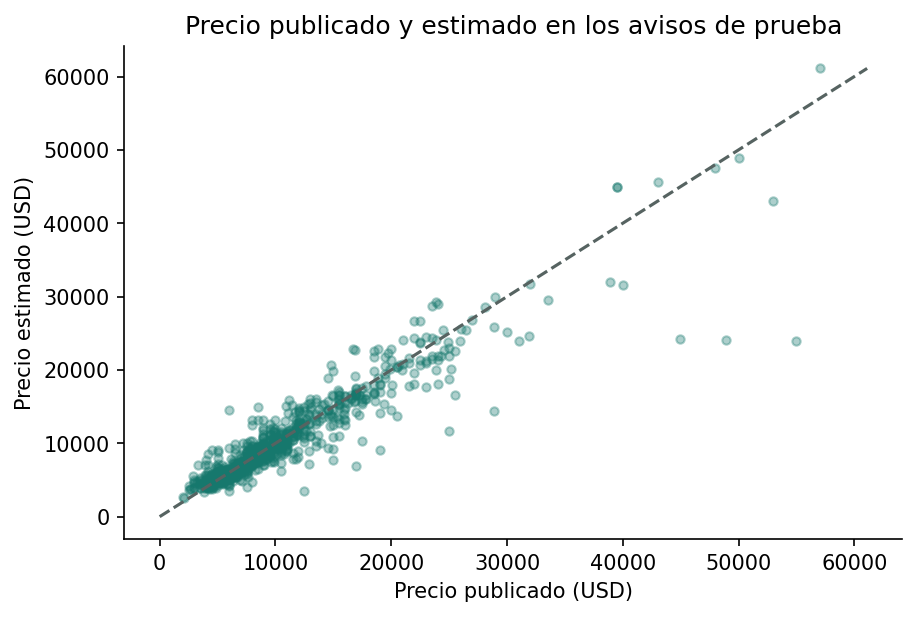

,brand,model,car_year,km,price,estimado_usd,error_absoluto_usd
3272,Ford,Ranger Raptor,2022,41500,55000,23928.08,31071.92
3233,Ford,Ranger Raptor,2020,55533,48900,24069.44,24830.56
3256,Ford,Ranger Raptor,2021,45000,44900,24151.99,20748.01


In [10]:
figura, eje = plt.subplots(figsize=(6, 4), layout="constrained")
eje.scatter(y_test, prediccion, alpha=0.35, s=16, color="#16786d")
limite = max(y_test.max(), prediccion.max())
eje.plot([0, limite], [0, limite], linestyle="--", color="#566361")
eje.set(
    title="Precio publicado y estimado en los avisos de prueba",
    xlabel="Precio publicado (USD)",
    ylabel="Precio estimado (USD)",
)
plt.show()

errores = autos.loc[X_test.index, ["brand", "model", "car_year", "km", "price"]].copy()
errores["estimado_usd"] = prediccion
errores["error_absoluto_usd"] = (errores["price"] - errores["estimado_usd"]).abs()
display(errores.nlargest(3, "error_absoluto_usd").round(2))

## 9. Probá una estimación

Este ejemplo usa un auto de 2014 con 108.000 km, motor de 1,6 L, 105 hp, cinco puertas y cinco plazas. Cambiá los valores para probar otra ficha. Podés usar `None` en un dato opcional si no lo conocés.

In [11]:
ejemplo = pd.DataFrame({
    "car_year": [2014],
    "km": [108000],
    "cilindrada": [1.6],
    "potencia": [105],
    "doors": [5],
    "passenger_capacity": [5],
})
estimacion = modelo.predict(ejemplo)[0]
print(f"Precio publicado estimado: USD {estimacion:,.2f}")

Precio publicado estimado: USD 8,417.23


## 10. Conclusiones

El precio mediano de la muestra es de USD 8.700. Los avisos de autos más nuevos tienden a ser más caros y los de autos con más kilómetros, más baratos. La comparación por marca resume los precios pedidos de esta muestra.

Elegimos **k-NN (5 vecinos, pesos por distancia)** porque obtuvo el menor MAE en validación: USD 1.539,76. En los 809 avisos de prueba obtuvo un MAE de **USD 1.406,86**, un RMSE de USD 2.625,82 y un R² de 0,866. El MAE fue un 69,6 % menor que el de la mediana de entrenamiento (USD 4.630,71).

Los tres errores más grandes fueron Ford Ranger Raptor cuyo precio publicado superaba ampliamente la estimación. Dos autos parecidos en las seis variables pueden tener precios distintos por el modelo, la versión, el estado o el equipamiento. Agregar esa información y conseguir avisos más recientes serían los próximos pasos.

El resultado describe avisos históricos de la misma fuente. La separación por filas puede dejar fichas parecidas en ambos conjuntos. Para estimar el precio de venta o evaluar el error en otro momento o mercado se necesitarían datos adicionales.